# Instructions

- This homework assignment is worth **78** points. 
- Please strive for clarity and organization.
- **AI Usage**:
   - AI use is strictly **prohibited** for conceptual exercises.
   - For applied (Python) exercises, you may only use AI for **debugging**. Do not use AI to generate answers.
- **Due Date: October 30, 2026, by 11:59 PM.**

# Exercise 1 

You are working with a dataset containing sales information (shown below), but the data has several inconsistencies and formatting issues. Your task is to clean the data using Python, focusing on applying proper formatting, while following good coding practices (such as readable variable names, comments, consistent indentation, and use of functions). You will fix issues related to missing values, incorrect data types, string inconsistencies, and extra whitespaces.

| Customer ID | Name | Age | Gender | Purchase Amount | Purchase Date | Payment Method | Location |
| -------- | ------- | ------- | ------- | ------- | ------- | ------- | ------- |
| 1 | John Doe | 45 | Male | 2500.50 | 2023-01-15 | Creditcard | New York |
| 2 | jennifer Smith | 34 | female | 180.75 | 2022/05/12 | Bank Transfer | San Francisco |
| 3 | Ron Miller | NaN | Male | 500.0 | 2023/03/14 | PayPal | NewYork |
| 4 | Mary Johnson | 29 | Female | -120.00 | 2023-07-30 | Credit Card | Los Angeles |
| 5 | Tim Lewis | 41 | male | 75.0 | 2023-02-15 | cash | San Francisco |

### Exercise 1(a) (2 points)

Load `pandas` and `numpy`.

In [1]:
import pandas as pd
import numpy as np

### Exercise 1(b) (3 points)

Create a data frame called `df` with the below data dictionary.

```
data = {
    'Customer ID': [1, 2, 3, 4, 5],
    'Name': ['John Doe', 'jennifer Smith', 'Ron Miller', 'Mary Johnson', 'Tim Lewis'],
    'Age': [45, 34, np.nan, 29, 41],
    'Gender': ['Male', 'female', 'Male', 'Female', 'male'],
    'Purchase Amount': [2500.50, 180.75, 500.0, -120.00, 75.0],
    'Purchase Date': ['2023-01-15', '2022/05/12', '2023/03/14', '2023-07-30', '2023-02-15'],
    'Payment Method': ['Creditcard', 'Bank Transfer', 'PayPal', 'Credit Card', 'cash'],
    'Location': ['New York', 'San Francisco', 'NewYork', 'Los Angeles', 'San Francisco']
}
```

In [2]:
# Create a dictionary containing customer sales data
data = {
    'Customer ID': [1, 2, 3, 4, 5],
    'Name': ['John Doe', 'jennifer Smith', 'Ron Miller', 'Mary Johnson', 'Tim Lewis'],
    'Age': [45, 34, np.nan, 29, 41],
    'Gender': ['Male', 'female', 'Male', 'Female', 'male'],
    'Purchase Amount': [2500.50, 180.75, 500.0, -120.00, 75.0],
    'Purchase Date': ['2023-01-15', '2022/05/12', '2023/03/14', '2023-07-30', '2023-02-15'],
    'Payment Method': ['Creditcard', 'Bank Transfer', 'PayPal', 'Credit Card', 'cash'],
    'Location': ['New York', 'San Francisco', 'NewYork', 'Los Angeles', 'San Francisco']
}

# Convert the dictionary into a pandas DataFrame
df = pd.DataFrame(data)

# Display the DataFrame
df

,Customer ID,Name,Age,Gender,Purchase Amount,Purchase Date,Payment Method,Location
0,1,John Doe,45.0,Male,2500.50,2023-01-15,Creditcard,New York
1,2,jennifer Smith,34.0,female,180.75,2022/05/12,Bank Transfer,San Francisco
2,3,Ron Miller,NaN,Male,500.00,2023/03/14,PayPal,NewYork
3,4,Mary Johnson,29.0,Female,-120.00,2023-07-30,Credit Card,Los Angeles
4,5,Tim Lewis,41.0,male,75.00,2023-02-15,cash,San Francisco


### Exercise 1(c) (15 points)

Create a function that perfoms the below cleaning steps. Ensure that your code is well-formatted and uses good practices like function definitions, variable names, and comments.

- Standardize the `Gender` column:
    - Ensure that all values in the `Gender` column are either `Male` or `Female` (proper case).

- Handle missing values in the `Age` column:
    - Fill the missing values in the `Age` column with the average age of all customers.

- Fix formatting issues in the `Purchase Date` column:
    - Ensure all dates are in the format `YYYY-MM-DD`.

- Correct invalid values in the `Purchase Amount` column:
    - Replace any negative purchase amounts with their absolute values.

- Fix the `Payment Method` column:
    - Standardize the payment methods (`Creditcard`, `Credit Card` -> `Credit Card`).

- Remove extra spaces and correct inconsistent locations:
    - Remove any extra spaces in the `Location` column and ensure consistent formatting (e.g., `NewYork` -> `New York`).

- Write a function:
    - Create a function that performs all of the above cleaning steps in a single process and returns the cleaned DataFrame.

The expected output of the function should be:

| Customer ID | Name | Age | Gender | Purchase Amount | Purchase Date | Payment Method | Location |
| -------- | ------- | ------- | ------- | ------- | ------- | ------- | ------- |
| 1 | John Doe | 45 | Male | 2500.50 | 2023-01-15 | Credit Card | New York |
| 2 | jennifer Smith | 34 | Female | 180.75 | 2022-05-12 | Bank Transfer | San Francisco |
| 3 | Ron Miller | 37.25 | Male | 500.0 | 2023-03-14 | PayPal | New York |
| 4 | Mary Johnson | 29 | Female | 120.00 | 2023-07-30 | Credit Card | Los Angeles |
| 5 | Tim Lewis | 41 | Male | 75.0 | 2023-02-15 | Cash | San Francisco |

In [3]:
# Define a function to clean the customer sales data
def clean_sales_data(df):

    # Create a copy to preserve the original DataFrame
    cleaned_df = df.copy()

    # 1. Standardize Gender values
    cleaned_df['Gender'] = cleaned_df['Gender'].str.strip().str.title()

    # 2. Fill missing Age values with the average age
    average_age = cleaned_df['Age'].mean()
    cleaned_df['Age'] = cleaned_df['Age'].fillna(average_age)

    # 3. Standardize Purchase Date to YYYY-MM-DD
    cleaned_df['Purchase Date'] = (
        cleaned_df['Purchase Date']
        .str.replace('/', '-', regex=False)
    )
    cleaned_df['Purchase Date'] = pd.to_datetime(
        cleaned_df['Purchase Date']
    ).dt.strftime('%Y-%m-%d')

    # 4. Convert negative Purchase Amount values to positive
    cleaned_df['Purchase Amount'] = cleaned_df['Purchase Amount'].abs()

    # 5. Standardize Payment Method values
    cleaned_df['Payment Method'] = (
        cleaned_df['Payment Method']
        .str.strip()
        .str.replace('Creditcard', 'Credit Card', regex=False)
    )
    cleaned_df['Payment Method'] = (
        cleaned_df['Payment Method']
        .replace({'cash': 'Cash'})
    )

    # 6. Remove extra spaces and standardize Location values
    cleaned_df['Location'] = (
        cleaned_df['Location']
        .str.strip()
        .str.replace(r'\s+', ' ', regex=True)
        .replace({'NewYork': 'New York'})
    )

    # Return the cleaned DataFrame
    return cleaned_df


# Apply the cleaning function to the original DataFrame
cleaned_df = clean_sales_data(df)

# Display the cleaned data
cleaned_df

,Customer ID,Name,Age,Gender,Purchase Amount,Purchase Date,Payment Method,Location
0,1,John Doe,45.00,Male,2500.50,2023-01-15,Credit Card,New York
1,2,jennifer Smith,34.00,Female,180.75,2022-05-12,Bank Transfer,San Francisco
2,3,Ron Miller,37.25,Male,500.00,2023-03-14,PayPal,New York
3,4,Mary Johnson,29.00,Female,120.00,2023-07-30,Credit Card,Los Angeles
4,5,Tim Lewis,41.00,Male,75.00,2023-02-15,Cash,San Francisco


# Exercise 2 

In this exercise, we will explore the `shopping_trends.csv` data file. The Customer Shopping Preferences Dataset offers valuable insights into consumer behavior and purchasing patterns. Understanding customer preferences and trends is critical for businesses to tailor their products, marketing strategies, and overall customer experience. This dataset captures a wide range of customer attributes including age, gender, purchase history, preferred payment methods, frequency of purchases, and more. Analyzing this data can help businesses make informed decisions, optimize product offerings, and enhance customer satisfaction. The dataset stands as a valuable resource for businesses aiming to align their strategies with customer needs and preferences. A brief description of each of the columns in the data set is presented below.


- `Customer ID`: Unique identifier for each customer
- `Age`: Age of the customer
- `Gender`: Gender of the customer (Male/Female)
- `Item Purchased`: The item purchased by the customer
- `Category`: Category of the item purchased
- `Purchase Amount (USD)`: The amount of the purchase in USD
- `Location`: Location where the purchase was made
- `Size`: Size of the purchased item
- `Color`: Color of the purchased item
- `Season`: Season during which the purchase was made
- `Review Rating`: Rating given by the customer for the purchased item
- `Subscription Status`: Indicates if the customer has a subscription (Yes/No)
- `Shipping Type`: Type of shipping chosen by the customer
- `Discount Applied`: Indicates if a discount was applied to the purchase (Yes/No)
- `Promo Code Used`: Indicates if a promo code was used for the purchase (Yes/No)
- `Previous Purchases`: The total count of transactions concluded by the customer at the store, excluding the ongoing transaction
- `Payment Method`: Customer's most preferred payment method
- `Frequency of Purchases`: Frequency at which the customer makes purchases (e.g., Weekly, Fortnightly, Monthly)

### Exercise 2(a) (2 points)

Load `pandas`, `matplotlib`, and `seaborn`


In [5]:
import micropip
await micropip.install('seaborn')

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Exercise 2(b) (2 points)

Read the `shopping_trends.csv` data file and create a data frame called `df`.

In [7]:
# Read the shopping trends CSV file into a DataFrame
df = pd.read_csv('shopping_trends.csv')

# Display the first 5 rows of the DataFrame
df.head()

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Payment Method,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Preferred Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Credit Card,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Bank Transfer,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Cash,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,PayPal,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Cash,Free Shipping,Yes,Yes,31,PayPal,Annually


### Exercise 2(c) (2 points)

Drop the `Customer ID` column.

In [8]:
# Drop the Customer ID column from the DataFrame
df = df.drop(columns=['Customer ID'])

# Display the first 5 rows of the updated DataFrame
df.head()

,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Payment Method,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Preferred Payment Method,Frequency of Purchases
0,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Credit Card,Express,Yes,Yes,14,Venmo,Fortnightly
1,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Bank Transfer,Express,Yes,Yes,2,Cash,Fortnightly
2,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Cash,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,PayPal,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Cash,Free Shipping,Yes,Yes,31,PayPal,Annually


### Exercise 2(d) (4 points)

Visualize the distribution of `Age`. Describe the chart.

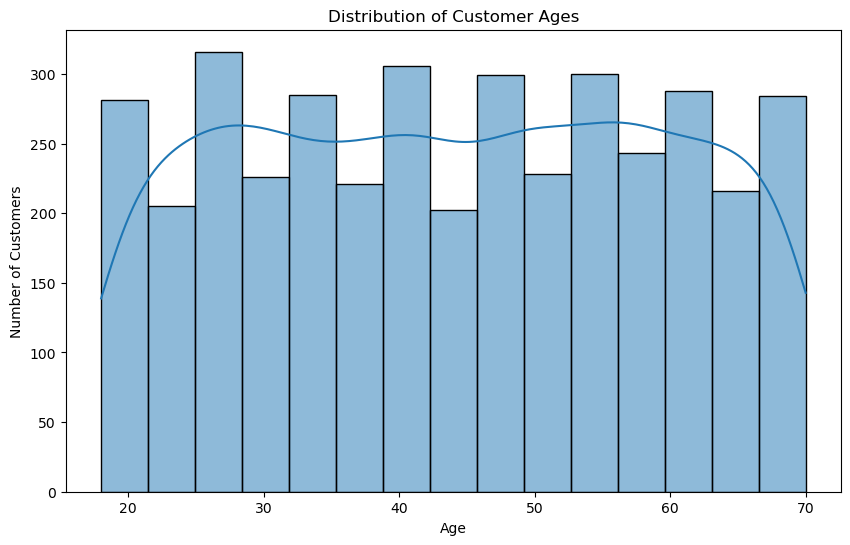

In [9]:
# Create a histogram to visualize the distribution of customer ages
plt.figure(figsize=(10, 6))

sns.histplot(data=df, x='Age', bins=15, kde=True)

# Add chart title and axis labels
plt.title('Distribution of Customer Ages')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

# Display the chart
plt.show()

The histogram illustrates the distribution of customer ages, ranging from 18 to 70 years old. The average customer age is approximately 44.07 years. Customers are relatively evenly distributed across most age groups, with no single age range dominating the dataset. This suggests that the business attracts customers from a broad range of ages rather than primarily serving one particular age group.

### Exercise 2(e) (2 points)

What is the most popular product category?

In [10]:
# Count the number of purchases in each product category
category_counts = df['Category'].value_counts()

# Display the most popular product category
print("Most Popular Product Category:", category_counts.idxmax())
print("Number of Purchases:", category_counts.max())

Most Popular Product Category: Clothing
Number of Purchases: 1737


### Exercise 2(f) (3 points)

What is the average purchase amount for each product category?

In [11]:
# Calculate the average purchase amount for each product category
average_purchase = df.groupby('Category')['Purchase Amount (USD)'].mean()

# Display the average purchase amount rounded to 2 decimal places
print(average_purchase.round(2))

Category
Accessories    59.84
Clothing       60.03
Footwear       60.26
Outerwear      57.17
Name: Purchase Amount (USD), dtype: float64


### Exercise 2(g) (3 points)

What is the percentage of customers who have applied discounts on their purchases?

In [12]:
# Calculate the percentage of customers who used a discount
discount_percentage = (df['Discount Applied'] == 'Yes').mean() * 100

# Display the percentage rounded to 2 decimal places
print(f"Percentage of customers who applied discounts: {discount_percentage:.2f}%")

Percentage of customers who applied discounts: 43.00%


### Exercise 2(h) (6 points)

How does purchase amount vary across different payment methods? Create an appropriate chart that can help to answer this question.

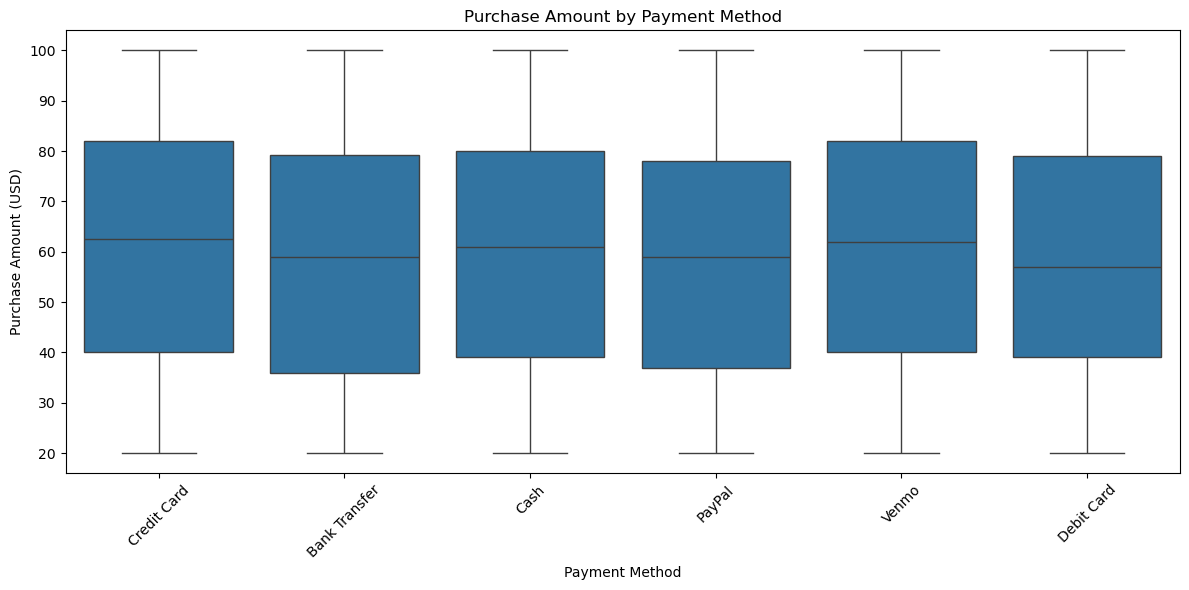

In [13]:
# Create a box plot to compare purchase amounts by payment method
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x='Payment Method',
    y='Purchase Amount (USD)'
)

# Add chart title and axis labels
plt.title('Purchase Amount by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Purchase Amount (USD)')

# Rotate labels for better readability
plt.xticks(rotation=45)

# Adjust layout and display the chart
plt.tight_layout()
plt.show()

The box plot compares customer purchase amounts across six different payment methods: Bank Transfer, Cash, Credit Card, Debit Card, PayPal, and Venmo.

Overall, purchase amounts are relatively similar across payment methods. Venmo has the highest average purchase amount at $61.24, followed closely by Credit Card at $61.16. Debit Card has the lowest average at $58.64. The median purchase amounts range from $57.00 to $62.50.

These findings suggest that payment method does not appear to have a substantial relationship with how much customers spend, although there are minor differences between methods.

### Exercise 2(i) (3 points)

What is the average number of previous purchases per customer?

In [14]:
# Calculate the average number of previous purchases per customer
average_previous_purchases = df['Previous Purchases'].mean()

# Display the average rounded to 2 decimal places
print(f"Average Previous Purchases: {average_previous_purchases:.2f}")


Average Previous Purchases: 25.35


### Exercise 2(j) (5 points)

Is there a relationship between `Purchase Amount (USD)` and `Review Rating`? Create the appropriate chart to answer this question.

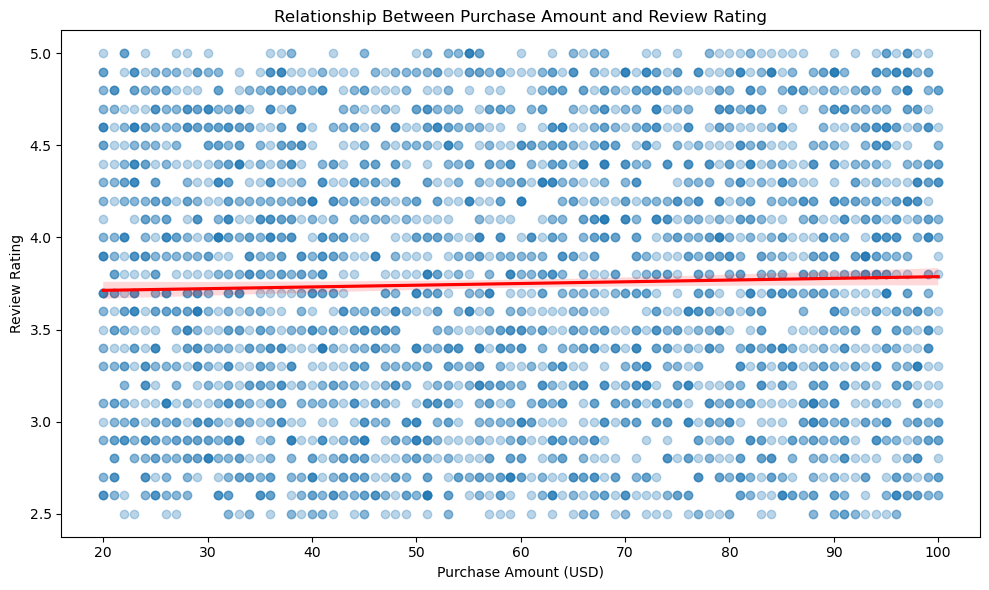

Correlation: 0.0308


In [15]:
# Create a scatter plot to examine the relationship
# between purchase amount and review rating
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x='Purchase Amount (USD)',
    y='Review Rating',
    scatter_kws={'alpha': 0.3},
    line_kws={'color': 'red'}
)

# Add chart title and axis labels
plt.title('Relationship Between Purchase Amount and Review Rating')
plt.xlabel('Purchase Amount (USD)')
plt.ylabel('Review Rating')

# Adjust layout and display the chart
plt.tight_layout()
plt.show()

# Calculate the correlation coefficient
correlation = df['Purchase Amount (USD)'].corr(df['Review Rating'])

print(f"Correlation: {correlation:.4f}")

The scatter plot examines the relationship between purchase amount and customer review rating. The x-axis represents the purchase amount in USD, while the y-axis represents the review rating.

The data points are widely scattered, and the regression line is nearly flat, suggesting little to no relationship between the two variables. The correlation coefficient is approximately 0.0308, indicating an extremely weak positive correlation.

Overall, the results suggest that customers who spend more money do not necessarily provide higher review ratings. Purchase amount does not appear to be a meaningful predictor of customer satisfaction in this dataset.

### Exercise 2(k) (3 points)

What percentage of customers use a subscription service?

In [16]:
# Calculate the percentage of customers with a subscription
subscription_percentage = (df['Subscription Status'] == 'Yes').mean() * 100

# Display the percentage rounded to 2 decimal places
print(f"Percentage of customers with a subscription: {subscription_percentage:.2f}%")

Percentage of customers with a subscription: 27.00%


### Exercise 2(l) (5 points)

What is the frequency of different shipping types selected by customers? Create the appropriate chart to answer this question.

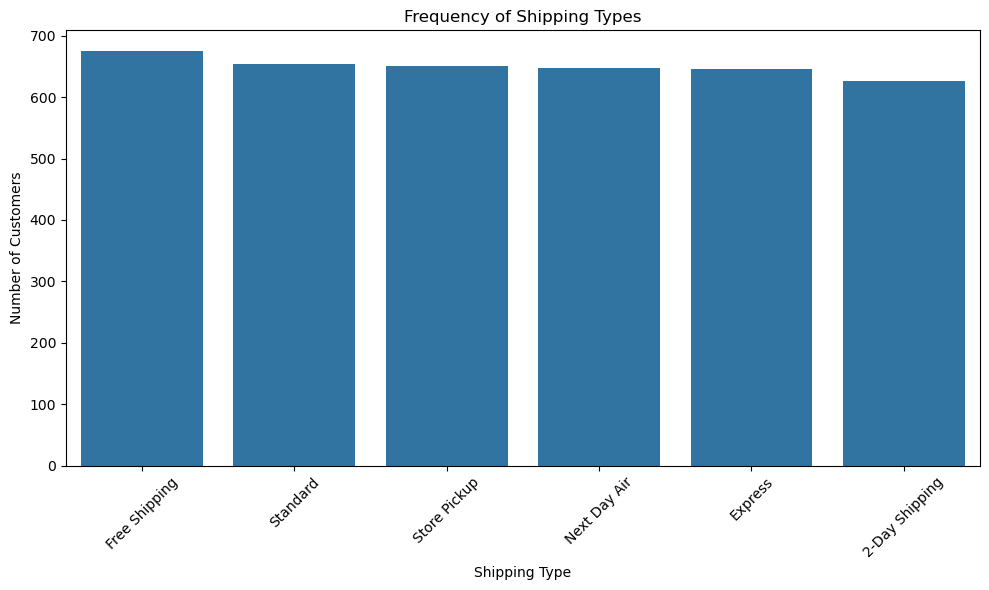

Shipping Type
Free Shipping     675
Standard          654
Store Pickup      650
Next Day Air      648
Express           646
2-Day Shipping    627
Name: count, dtype: int64


In [17]:
# Count the frequency of each shipping type
shipping_counts = df['Shipping Type'].value_counts()

# Create a bar chart showing shipping type frequencies
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x='Shipping Type',
    order=shipping_counts.index
)

# Add chart title and axis labels
plt.title('Frequency of Shipping Types')
plt.xlabel('Shipping Type')
plt.ylabel('Number of Customers')

# Rotate labels for readability
plt.xticks(rotation=45)

# Adjust layout and display the chart
plt.tight_layout()
plt.show()

# Display the frequency counts
print(shipping_counts)

The bar chart illustrates the frequency of different shipping methods selected by customers. Free Shipping is the most frequently selected option, with 675 purchases, followed by Standard Shipping with 654 and Store Pickup with 650. Next Day Air and Express Shipping are also commonly selected, with 648 and 646 purchases, respectively. Two-Day Shipping is the least frequently selected option, with 627 purchases.

Overall, the frequencies are relatively similar across all six shipping methods. This suggests that customers have diverse shipping preferences, with a slight preference for Free Shipping.

# Exercise 3

Formatters, linters, and type checkers each answer a different question about your code, and none of them requires running it.

### Exercise 3(a) (5 points)

For each of the following situations, state which tool (a **formatter** such as Black, a **linter** such as Ruff or Flake8, or a **type checker** such as mypy) is designed to detect or fix it, and explain why the other two tools would not.

1. The line `ax.plot(n, big_o[ i], label= line_names[i ])` has stray whitespace inside the brackets and around the keyword-argument equals sign.
2. A function calls `np.mean(values)`, but `numpy` was never imported.
3. A function annotated as `def load(path: str) -> str | None` is used as `load("model.yaml").upper()`.

**1. Formatter (Black):** A formatter fixes unnecessary spaces and makes the code more consistent and readable. A linter focuses on identifying coding mistakes, while a type checker looks for data type errors rather than formatting issues.

**2. Linter (Ruff or Flake8):** A linter detects that `np` is being used without importing NumPy. A formatter would only adjust the appearance of the code, while a type checker focuses primarily on whether data types are being used correctly, although it may also detect undefined names.

**3. Type Checker (mypy):** A type checker detects that the function could return either a string or `None`. Since `None` does not support `.upper()`, this could cause an error. A formatter would only fix the code's appearance, while a typical linter would not perform this level of type checking.

### Exercise 3(b) (4 points)

A teammate says: "I have format-on-save and linting turned on in my editor, so we do not need pre-commit hooks or continuous integration." Do you agree? Explain your answer in two to three sentences.

I disagree because format-on-save and linting only check code in an individual's editor, and not everyone on the team may have the same settings. Pre-commit hooks help catch issues before code is committed, while continuous integration automatically checks the code after it is pushed to make sure everything works correctly. Using all three helps maintain consistent code quality and reduces errors when working as a team.

# Exercise 4

The function below runs and returns the correct answer, but it violates many of the conventions discussed in Chapter 6. It is supposed to compute the average of the values in a column that are strictly greater than a threshold, and to return `None` if no value qualifies.

```python
import sys, os
import pandas as pd
import numpy as np

def AvgPositive(DF,col,min = 0 ):
    sum=0
    count=0
    for i in range(len(DF)):
        if DF[col][i] > min: sum = sum + DF[col][i]; count = count + 1
    if count == 0: return None
    return sum/count
```

### Exercise 4(a) (5 points)

Rewrite the function so that it follows PEP8 and the naming conventions from Chapter 6. At a minimum, your version must:

- Import only the modules it needs, one per line.
- Use descriptive `snake_case` names for the function, its parameters, and its variables.
- Not shadow any Python builtins.
- Put each statement on its own line, use four-space indentation, and use the correct number of blank lines.
- Include a docstring.

You may keep the loop or replace it with a vectorized `pandas` expression.

In [18]:
import pandas as pd


def average_above_threshold(dataframe, column_name, threshold=0):
    """
    Calculate the average of values greater than a given threshold.

    Returns None if no values meet the condition.
    """
    total = 0
    count = 0

    for value in dataframe[column_name]:
        if value > threshold:
            total += value
            count += 1

    if count == 0:
        return None

    return total / count

### Exercise 4(b) (4 points)

Add type annotations to your function from 4(a), using the modern syntax (e.g., `str | None`). Then use it to:

1. Compute the average of the strictly positive values of `Purchase Amount (USD)` in `shopping_trends.csv`.
2. Call the function on a small data frame where no value is above the threshold, and show that it returns `None`.

Finally, in a comment, state what error `mypy` would report for the call `average_positive("Purchase Amount (USD)", df)` (arguments in the wrong order), and whether Python itself would complain about the annotations before the function body runs.

In [19]:
import pandas as pd


def average_above_threshold(
    dataframe: pd.DataFrame,
    column_name: str,
    threshold: float = 0
) -> float | None:
    """
    Calculate the average of values greater than a threshold.

    Return None if no values qualify.
    """
    total = 0.0
    count = 0

    for value in dataframe[column_name]:
        if value > threshold:
            total += value
            count += 1

    if count == 0:
        return None

    return total / count


# Test 1: Average of strictly positive purchase amounts
average_purchase = average_above_threshold(
    df, "Purchase Amount (USD)"
)

print("Average Positive Purchase Amount:", average_purchase)


# Test 2: DataFrame with no values above the threshold
test_df = pd.DataFrame({"Values": [-10, -5, 0]})

no_positive_average = average_above_threshold(
    test_df, "Values"
)

print("Average with No Positive Values:", no_positive_average)


# Test 3: Explain the incorrect argument order
# mypy would report incompatible argument types:
# Argument 1 expects pd.DataFrame but receives str.
# Argument 2 expects str but receives pd.DataFrame.
# Python does not enforce these annotations at runtime.
# It would enter the function body and then raise an error
# when trying to use the arguments in the wrong order.

Average Positive Purchase Amount: 59.76435897435898
Average with No Positive Values: None
